<a href="https://colab.research.google.com/github/sorayanakhbaty/Dicoding_Analisis-Sentimen/blob/main/Dicoding_Analisis_Sentimen_Soraya_Nakhbaty.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Import Library**

In [ ]:
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 7.9 MB/s eta 0:00:00


In [ ]:
import re
import string
import numpy as np
import pandas as pd
import seaborn as sns
import datetime as dt
import matplotlib.pyplot as plt

import csv
import requests
import tensorflow as tf
from io import StringIO

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk import download as nltk_download
nltk_download('punkt')
nltk_download('punkt_tab')
nltk_download('stopwords')
nltk_download('wordnet')

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from wordcloud import WordCloud

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score, precision_score
from sklearn.preprocessing import LabelEncoder

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D, Bidirectional, MaxPooling1D, Flatten, GRU, SimpleRNN, Conv1D, GlobalMaxPooling1D
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, Callback
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from keras.layers import LeakyReLU, BatchNormalization

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


# **Loading Dataset**

In [ ]:
# Read dataset
df = pd.read_csv('/content/ulasan_CapCut.csv')

In [ ]:
df.head()

,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,b147d079-e879-4135-837f-d8fef6b58c62,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,"sekarang mau edit-edit jadi lumayan susah, dul...",2,1761,15.1.0,2025-09-07 14:05:21,NaN,NaN,15.1.0
1,b83fca8e-98b1-4de0-96a3-d3845ca7b99a,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,Padahal dari dulu pakai aplikasi ini karna sim...,3,282,15.2.0,2025-09-24 18:40:19,Terima kasih atas umpan balik Anda. Dengan mem...,2025-09-26 04:14:12,15.2.0
2,09411fc8-947f-44ed-838b-48053ffea3d3,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,"ada pembayaran dibeberapa fitur, jadi saya cob...",1,1936,15.2.0,2025-09-27 08:07:34,NaN,NaN,15.2.0
3,611e931a-f1ec-4630-a49f-8d3d8937259b,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,Pay to edit 😭 Nyebelin banget dikit-dikit ikla...,1,2949,15.2.0,2025-09-24 08:44:29,NaN,NaN,15.2.0
4,8ea51cf8-ebe6-4aad-af64-ff44b9ef9b1e,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,saya sudah hampir dua tahun..pakai capcut tapi...,1,916,15.2.0,2025-09-28 08:35:34,NaN,NaN,15.2.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   reviewId              50000 non-null  object
 1   userName              50000 non-null  object
 2   userImage             50000 non-null  object
 3   content               49999 non-null  object
 4   score                 50000 non-null  int64 
 5   thumbsUpCount         50000 non-null  int64 
 6   reviewCreatedVersion  34041 non-null  object
 7   at                    50000 non-null  object
 8   replyContent          592 non-null    object
 9   repliedAt             592 non-null    object
 10  appVersion            34041 non-null  object
dtypes: int64(2), object(9)
memory usage: 4.2+ MB


# **Cleaning Data Scrapping**

In [ ]:
# Menghapus missing value pada kolom 'content'
clean_df = df.dropna(subset=['content'])

# Menghapus df duplikat
clean_df = clean_df.drop_duplicates()

In [ ]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49999 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   reviewId              49999 non-null  object
 1   userName              49999 non-null  object
 2   userImage             49999 non-null  object
 3   content               49999 non-null  object
 4   score                 49999 non-null  int64 
 5   thumbsUpCount         49999 non-null  int64 
 6   reviewCreatedVersion  34040 non-null  object
 7   at                    49999 non-null  object
 8   replyContent          592 non-null    object
 9   repliedAt             592 non-null    object
 10  appVersion            34040 non-null  object
dtypes: int64(2), object(9)
memory usage: 4.6+ MB


In [ ]:
clean_df = clean_df[['content']]
clean_df = clean_df.rename(columns={"content": "review"})
clean_df

,review
0,"sekarang mau edit-edit jadi lumayan susah, dul..."
1,Padahal dari dulu pakai aplikasi ini karna sim...
2,"ada pembayaran dibeberapa fitur, jadi saya cob..."
3,Pay to edit 😭 Nyebelin banget dikit-dikit ikla...
4,saya sudah hampir dua tahun..pakai capcut tapi...
...,...
49995,aplikasi kok Dikit2 usang mengekspornya lama t...
49996,"Tolong iklannya,di hapuskn,terkdg lg mnggunkn ..."
49997,Gillaaaaaaaaaaaaaaaaa bgus bat nih capcut tapi...
49998,"Mantapppppp! , saya berterima kasih kepada dev..."


In [ ]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49999 entries, 0 to 49999
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  49999 non-null  object
dtypes: object(1)
memory usage: 781.2+ KB


# **Preprocessing Data**

In [ ]:
# Mendefinisikan fungsi-fungsi untuk preprocessing text

def cleaningText(text):
    text = re.sub(r'@[A-Za-z0-9]+', '', text)
    text = re.sub(r'#[A-Za-z0-9]+', '', text)
    text = re.sub(r'RT[\s]', '', text)
    text = re.sub(r"http\S+", '', text)
    text = re.sub(r'[0-9]+', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    text = text.replace('\n', ' ')
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = text.strip(' ')
    return text

def casefoldingText(text):
    text = text.lower()
    return text

slangwords = {"@": "di", "abis": "habis", "wtb": "beli", "masi": "masih", "wts": "jual", "wtt": "tukar", "bgt": "banget", "maks": "maksimal"}
def fix_slangwords(text):
    words = text.split()
    fixed_words = []

    for word in words:
        if word.lower() in slangwords:
            fixed_words.append(slangwords[word.lower()])
        else:
            fixed_words.append(word)

    fixed_text = ' '.join(fixed_words)
    return fixed_text

def tokenizingText(text):
    text = word_tokenize(text)
    return text

def filteringText(text):
    listStopwords = set(stopwords.words('indonesian'))
    listStopwords1 = set(stopwords.words('english'))
    listStopwords.update(listStopwords1)
    listStopwords.update(['iya','yaa','gak','nya','na','sih','ku',"di","ga","ya","gaa","loh","kah","woi","woii","woy"])
    filtered = []
    for txt in text:
        if txt not in listStopwords:
            filtered.append(txt)
    text = filtered
    return text

def stemmingText(text):
    factory = StemmerFactory()
    stemmer = factory.create_stemmer()


    if isinstance(text, list):
        stemmed_words = [stemmer.stem(word) for word in text]
    else:
        words = text.split()
        stemmed_words = [stemmer.stem(word) for word in words]

    stemmed_text = ' '.join(stemmed_words)

    return stemmed_text

def toSentence(list_words):
    sentence = ' '.join(word for word in list_words)
    return sentence

In [ ]:
clean_df['text_clean'] = clean_df['review'].apply(cleaningText)
clean_df['text_casefoldingText'] = clean_df['text_clean'].apply(casefoldingText)
clean_df['text_slangwords'] = clean_df['text_casefoldingText'].apply(fix_slangwords)
clean_df['text_tokenizingText'] = clean_df['text_slangwords'].apply(tokenizingText)
clean_df['text_stopword'] = clean_df['text_tokenizingText'].apply(filteringText)
clean_df['final_text'] = clean_df['text_stopword'].apply(toSentence)

In [ ]:
clean_df

,review,text_clean,text_casefoldingText,text_slangwords,text_tokenizingText,text_stopword,final_text
0,"sekarang mau edit-edit jadi lumayan susah, dul...",sekarang mau editedit jadi lumayan susah dulu ...,sekarang mau editedit jadi lumayan susah dulu ...,sekarang mau editedit jadi lumayan susah dulu ...,"[sekarang, mau, editedit, jadi, lumayan, susah...","[editedit, lumayan, susah, tinggal, taptap, ar...",editedit lumayan susah tinggal taptap arahin a...
1,Padahal dari dulu pakai aplikasi ini karna sim...,Padahal dari dulu pakai aplikasi ini karna sim...,padahal dari dulu pakai aplikasi ini karna sim...,padahal dari dulu pakai aplikasi ini karna sim...,"[padahal, dari, dulu, pakai, aplikasi, ini, ka...","[pakai, aplikasi, karna, simpel, mudah, semenj...",pakai aplikasi karna simpel mudah semenjak pem...
2,"ada pembayaran dibeberapa fitur, jadi saya cob...",ada pembayaran dibeberapa fitur jadi saya coba...,ada pembayaran dibeberapa fitur jadi saya coba...,ada pembayaran dibeberapa fitur jadi saya coba...,"[ada, pembayaran, dibeberapa, fitur, jadi, say...","[pembayaran, dibeberapa, fitur, coba, fitur, b...",pembayaran dibeberapa fitur coba fitur berbaya...
3,Pay to edit 😭 Nyebelin banget dikit-dikit ikla...,Pay to edit Nyebelin banget dikitdikit iklan ...,pay to edit nyebelin banget dikitdikit iklan ...,pay to edit nyebelin banget dikitdikit iklan s...,"[pay, to, edit, nyebelin, banget, dikitdikit, ...","[pay, edit, nyebelin, banget, dikitdikit, ikla...",pay edit nyebelin banget dikitdikit iklan dipa...
4,saya sudah hampir dua tahun..pakai capcut tapi...,saya sudah hampir dua tahunpakai capcut tapi a...,saya sudah hampir dua tahunpakai capcut tapi a...,saya sudah hampir dua tahunpakai capcut tapi a...,"[saya, sudah, hampir, dua, tahunpakai, capcut,...","[tahunpakai, capcut, nggak, banget, trouble, b...",tahunpakai capcut nggak banget trouble bikin k...
...,...,...,...,...,...,...,...
49995,aplikasi kok Dikit2 usang mengekspornya lama t...,aplikasi kok Dikit usang mengekspornya lama ta...,aplikasi kok dikit usang mengekspornya lama ta...,aplikasi kok dikit usang mengekspornya lama ta...,"[aplikasi, kok, dikit, usang, mengekspornya, l...","[aplikasi, dikit, usang, mengekspornya, musik,...",aplikasi dikit usang mengekspornya musik jj la...
49996,"Tolong iklannya,di hapuskn,terkdg lg mnggunkn ...",Tolong iklannyadi hapusknterkdg lg mnggunkn ap...,tolong iklannyadi hapusknterkdg lg mnggunkn ap...,tolong iklannyadi hapusknterkdg lg mnggunkn ap...,"[tolong, iklannyadi, hapusknterkdg, lg, mnggun...","[tolong, iklannyadi, hapusknterkdg, lg, mnggun...",tolong iklannyadi hapusknterkdg lg mnggunkn ap...
49997,Gillaaaaaaaaaaaaaaaaa bgus bat nih capcut tapi...,Gillaaaaaaaaaaaaaaaaa bgus bat nih capcut tapi...,gillaaaaaaaaaaaaaaaaa bgus bat nih capcut tapi...,gillaaaaaaaaaaaaaaaaa bgus bat nih capcut tapi...,"[gillaaaaaaaaaaaaaaaaa, bgus, bat, nih, capcut...","[gillaaaaaaaaaaaaaaaaa, bgus, bat, nih, capcut...",gillaaaaaaaaaaaaaaaaa bgus bat nih capcut yg k...
49998,"Mantapppppp! , saya berterima kasih kepada dev...",Mantapppppp saya berterima kasih kepada devel...,mantapppppp saya berterima kasih kepada devel...,mantapppppp saya berterima kasih kepada develo...,"[mantapppppp, saya, berterima, kasih, kepada, ...","[mantapppppp, berterima, kasih, developer, cap...",mantapppppp berterima kasih developer capcut k...


In [ ]:
clean_df = clean_df.dropna()
print("Number of Reviews :", clean_df.shape[0])

Number of Reviews : 49999


In [ ]:
lexicon_positive = dict()

response = requests.get('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_positive.csv')
reader = csv.reader(StringIO(response.text), delimiter=',')
for row in reader:
    lexicon_positive[row[0]] = int(row[1])

lexicon_negative = dict()

response = requests.get('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_negative.csv')
reader = csv.reader(StringIO(response.text), delimiter=',')
for row in reader:
    lexicon_negative[row[0]] = int(row[1])

In [ ]:
def sentiment_analysis_lexicon_indonesia(text):
    score = 0
    for word in text.split():
        if (word in lexicon_positive):
            score = score + lexicon_positive[word]

    for word in text.split():
        if (word in lexicon_negative):
            score = score + lexicon_negative[word]

    polarity=''

    if (score > 0):
        polarity = 'positive'
    elif (score < 0):
        polarity = 'negative'
    else:
        polarity = 'neutral'

    return score, polarity

In [ ]:
results = clean_df['final_text'].apply(sentiment_analysis_lexicon_indonesia)
results = list(zip(*results))
clean_df['sentiment_score'] = results[0]
clean_df['sentiment'] = results[1]
print(clean_df['sentiment'].value_counts())

sentiment
negative    29712
positive    15920
neutral      4367
Name: count, dtype: int64


/tmp/ipython-input-1571625081.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='sentiment', data=clean_df, palette='viridis')


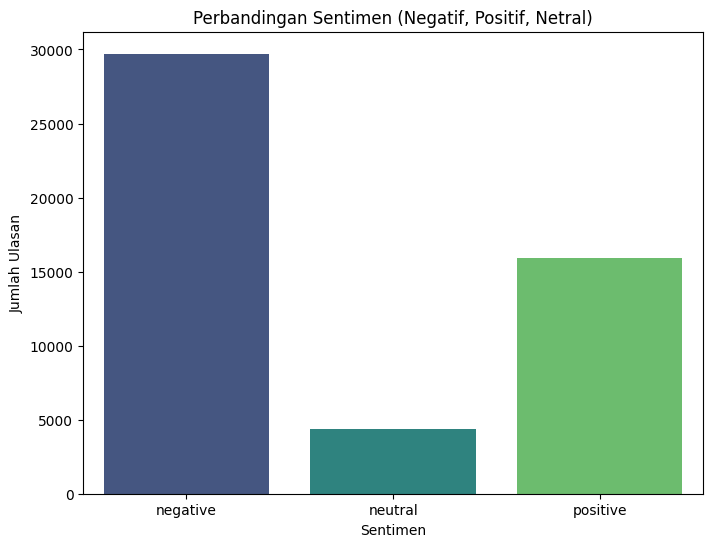

In [ ]:
plt.figure(figsize=(8, 6))
sns.countplot(x='sentiment', data=clean_df, palette='viridis')
plt.title('Perbandingan Sentimen (Negatif, Positif, Netral)')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah Ulasan')
plt.show()

# **Labeling**

In [ ]:
clean_df.to_csv('labeling_data.csv', index=False)

In [ ]:
df = clean_df
df

,review,text_clean,text_casefoldingText,text_slangwords,text_tokenizingText,text_stopword,final_text,sentiment_score,sentiment
0,"sekarang mau edit-edit jadi lumayan susah, dul...",sekarang mau editedit jadi lumayan susah dulu ...,sekarang mau editedit jadi lumayan susah dulu ...,sekarang mau editedit jadi lumayan susah dulu ...,"[sekarang, mau, editedit, jadi, lumayan, susah...","[editedit, lumayan, susah, tinggal, taptap, ar...",editedit lumayan susah tinggal taptap arahin a...,-10,negative
1,Padahal dari dulu pakai aplikasi ini karna sim...,Padahal dari dulu pakai aplikasi ini karna sim...,padahal dari dulu pakai aplikasi ini karna sim...,padahal dari dulu pakai aplikasi ini karna sim...,"[padahal, dari, dulu, pakai, aplikasi, ini, ka...","[pakai, aplikasi, karna, simpel, mudah, semenj...",pakai aplikasi karna simpel mudah semenjak pem...,-16,negative
2,"ada pembayaran dibeberapa fitur, jadi saya cob...",ada pembayaran dibeberapa fitur jadi saya coba...,ada pembayaran dibeberapa fitur jadi saya coba...,ada pembayaran dibeberapa fitur jadi saya coba...,"[ada, pembayaran, dibeberapa, fitur, jadi, say...","[pembayaran, dibeberapa, fitur, coba, fitur, b...",pembayaran dibeberapa fitur coba fitur berbaya...,-28,negative
3,Pay to edit 😭 Nyebelin banget dikit-dikit ikla...,Pay to edit Nyebelin banget dikitdikit iklan ...,pay to edit nyebelin banget dikitdikit iklan ...,pay to edit nyebelin banget dikitdikit iklan s...,"[pay, to, edit, nyebelin, banget, dikitdikit, ...","[pay, edit, nyebelin, banget, dikitdikit, ikla...",pay edit nyebelin banget dikitdikit iklan dipa...,-25,negative
4,saya sudah hampir dua tahun..pakai capcut tapi...,saya sudah hampir dua tahunpakai capcut tapi a...,saya sudah hampir dua tahunpakai capcut tapi a...,saya sudah hampir dua tahunpakai capcut tapi a...,"[saya, sudah, hampir, dua, tahunpakai, capcut,...","[tahunpakai, capcut, nggak, banget, trouble, b...",tahunpakai capcut nggak banget trouble bikin k...,-15,negative
...,...,...,...,...,...,...,...,...,...
49995,aplikasi kok Dikit2 usang mengekspornya lama t...,aplikasi kok Dikit usang mengekspornya lama ta...,aplikasi kok dikit usang mengekspornya lama ta...,aplikasi kok dikit usang mengekspornya lama ta...,"[aplikasi, kok, dikit, usang, mengekspornya, l...","[aplikasi, dikit, usang, mengekspornya, musik,...",aplikasi dikit usang mengekspornya musik jj la...,-12,negative
49996,"Tolong iklannya,di hapuskn,terkdg lg mnggunkn ...",Tolong iklannyadi hapusknterkdg lg mnggunkn ap...,tolong iklannyadi hapusknterkdg lg mnggunkn ap...,tolong iklannyadi hapusknterkdg lg mnggunkn ap...,"[tolong, iklannyadi, hapusknterkdg, lg, mnggun...","[tolong, iklannyadi, hapusknterkdg, lg, mnggun...",tolong iklannyadi hapusknterkdg lg mnggunkn ap...,0,neutral
49997,Gillaaaaaaaaaaaaaaaaa bgus bat nih capcut tapi...,Gillaaaaaaaaaaaaaaaaa bgus bat nih capcut tapi...,gillaaaaaaaaaaaaaaaaa bgus bat nih capcut tapi...,gillaaaaaaaaaaaaaaaaa bgus bat nih capcut tapi...,"[gillaaaaaaaaaaaaaaaaa, bgus, bat, nih, capcut...","[gillaaaaaaaaaaaaaaaaa, bgus, bat, nih, capcut...",gillaaaaaaaaaaaaaaaaa bgus bat nih capcut yg k...,0,neutral
49998,"Mantapppppp! , saya berterima kasih kepada dev...",Mantapppppp saya berterima kasih kepada devel...,mantapppppp saya berterima kasih kepada devel...,mantapppppp saya berterima kasih kepada develo...,"[mantapppppp, saya, berterima, kasih, kepada, ...","[mantapppppp, berterima, kasih, developer, cap...",mantapppppp berterima kasih developer capcut k...,-5,negative


In [ ]:
X = df['final_text'].values
y = df['sentiment'].values

In [ ]:
# Tokenisasi
max_features = 2500
tokenizer = Tokenizer(num_words=max_features, split=' ')
tokenizer.fit_on_texts(X)
X = tokenizer.texts_to_sequences(X)
X = pad_sequences(X)

# Label encoding
labelencoder = LabelEncoder()
integer_encoded = labelencoder.fit_transform(y)
y = to_categorical(integer_encoded)

# Menentukan jumlah kelas
num_classes = y.shape[1]

In [ ]:
class CustomCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if logs.get('accuracy') > 0.94:
            print(f"\nAccuracy has reached beyond 0.94, stopping training at epoch {epoch+1}")
            self.model.stop_training = True
early_stopping = CustomCallback()

# **RNN**

In [ ]:
# Separating training, validation, and test data
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=42)


In [ ]:
# Building a RNN model
model_RNN = Sequential()
model_RNN.add(Embedding(max_features, 512, input_length=X.shape[1]))
model_RNN.add(SimpleRNN(128, return_sequences=False)) # Use SimpleRNN layer
model_RNN.add(Dense(64, activation='relu'))
model_RNN.add(Dropout(0.5))
model_RNN.add(Dense(num_classes, activation='softmax'))
model_RNN.compile(loss='categorical_crossentropy', optimizer=Adam(learning_rate=0.001), metrics=['accuracy'])


# Train the model with custom early stopping
batch_size = 2056
history_RNN = model_RNN.fit(X_train, y_train, epochs=10, batch_size=batch_size, verbose=2, callbacks=[early_stopping], validation_data=(X_val, y_val))

Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


20/20 - 10s - 502ms/step - accuracy: 0.5476 - loss: 0.9250 - val_accuracy: 0.6042 - val_loss: 0.8305
Epoch 2/10
20/20 - 2s - 76ms/step - accuracy: 0.6973 - loss: 0.7234 - val_accuracy: 0.7976 - val_loss: 0.5417
Epoch 3/10
20/20 - 2s - 76ms/step - accuracy: 0.8409 - loss: 0.4503 - val_accuracy: 0.8556 - val_loss: 0.4108
Epoch 4/10
20/20 - 2s - 123ms/step - accuracy: 0.8882 - loss: 0.3229 - val_accuracy: 0.8744 - val_loss: 0.3557
Epoch 5/10
20/20 - 1s - 71ms/step - accuracy: 0.9080 - loss: 0.2636 - val_accuracy: 0.8942 - val_loss: 0.3137
Epoch 6/10
20/20 - 1s - 72ms/step - accuracy: 0.9263 - loss: 0.2226 - val_accuracy: 0.8938 - val_loss: 0.3174
Epoch 7/10
20/20 - 1s - 71ms/step - accuracy: 0.9345 - loss: 0.1958 - val_accuracy: 0.8953 - val_loss: 0.2972
Epoch 8/10

Accuracy has reached beyond 0.94, stopping training at epoch 8
20/20 - 1s - 72ms/step - accuracy: 0.9422 - loss: 0.1747 - val_accuracy: 0.8922 - val_loss: 0.3106


In [ ]:
# Model Evaluation
score_RNN, acc_RNN = model_RNN.evaluate(X_test, y_test, verbose=2)
print("Test accuracy: %.2f" % (acc_RNN))

157/157 - 1s - 9ms/step - accuracy: 0.8946 - loss: 0.3181
Test accuracy: 0.89


In [ ]:
# Save Model
model_RNN.save('model_RNN.keras')

# **LSTM**

In [ ]:
# Separating training, validation, and test data
X_train_val, X_testLSTM, y_train_val, y_testLSTM = train_test_split(X, y, test_size=0.1, random_state=42)

X_trainLSTM, X_valLSTM, y_trainLSTM, y_valLSTM = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=42)


In [ ]:
# Building a LSTM model
model_LSTM = Sequential()
model_LSTM.add(Embedding(max_features, 256, input_length=X.shape[1]))
model_LSTM.add(LSTM(128, dropout=0.2, recurrent_dropout=0.2, kernel_regularizer=l2(0.01), return_sequences=True))
model_LSTM.add(LSTM(64, dropout=0.2, recurrent_dropout=0.2, kernel_regularizer=l2(0.01)))
model_LSTM.add(Dense(128, activation='relu'))
model_LSTM.add(Dense(64, activation='relu'))
model_LSTM.add(Dense(num_classes, activation='softmax'))
model_LSTM.compile(loss='categorical_crossentropy', optimizer=Adam(learning_rate=0.001), metrics=['accuracy'])

# Train the model with custom early stopping
batch_size = 64
history_LSTM = model_LSTM.fit(X_trainLSTM, y_trainLSTM, epochs=10, batch_size=batch_size, verbose=2, callbacks=[early_stopping], validation_data=(X_valLSTM, y_valLSTM))

Epoch 1/10
633/633 - 314s - 496ms/step - accuracy: 0.7498 - loss: 0.8732 - val_accuracy: 0.8702 - val_loss: 0.3968
Epoch 2/10
633/633 - 294s - 465ms/step - accuracy: 0.8867 - loss: 0.3507 - val_accuracy: 0.8998 - val_loss: 0.3080
Epoch 3/10
633/633 - 300s - 474ms/step - accuracy: 0.9046 - loss: 0.2991 - val_accuracy: 0.8818 - val_loss: 0.3374
Epoch 4/10
633/633 - 296s - 468ms/step - accuracy: 0.9145 - loss: 0.2753 - val_accuracy: 0.9136 - val_loss: 0.2765
Epoch 5/10
633/633 - 294s - 465ms/step - accuracy: 0.9189 - loss: 0.2580 - val_accuracy: 0.9098 - val_loss: 0.2788
Epoch 6/10
633/633 - 296s - 467ms/step - accuracy: 0.9231 - loss: 0.2467 - val_accuracy: 0.9082 - val_loss: 0.2867
Epoch 7/10
633/633 - 296s - 467ms/step - accuracy: 0.9270 - loss: 0.2376 - val_accuracy: 0.9109 - val_loss: 0.2788
Epoch 8/10
633/633 - 296s - 468ms/step - accuracy: 0.9272 - loss: 0.2335 - val_accuracy: 0.9156 - val_loss: 0.2803
Epoch 9/10
633/633 - 303s - 479ms/step - accuracy: 0.9309 - loss: 0.2225 - val_a

In [ ]:
# Model Evaluation
score_LSTM, acc_LSTM = model_LSTM.evaluate(X_testLSTM, y_testLSTM, verbose=2)
print("Test accuracy: %.2f" % (acc_LSTM))

157/157 - 13s - 84ms/step - accuracy: 0.9158 - loss: 0.2698
Test accuracy: 0.92


In [ ]:
# Save Model
model_LSTM.save('model_LSTM.keras')

# **GRU**

In [ ]:
# Separating training, validation, and test data
X_train_val, X_testGRU, y_train_val, y_testGRU = train_test_split(X, y, test_size=0.05, random_state=42)

X_trainGRU, X_valGRU, y_trainGRU, y_valGRU = train_test_split(X_train_val, y_train_val, test_size=0.05, random_state=42)

In [ ]:
model_GRU = Sequential()
model_GRU.add(Embedding(max_features, 512, input_length=X.shape[1]))
model_GRU.add(SpatialDropout1D(0.3))
model_GRU.add(Bidirectional(GRU(64, return_sequences=True)))
model_GRU.add(Bidirectional(GRU(128, return_sequences=False)))
model_GRU.add(Dense(128, activation='relu',kernel_regularizer=l2(0.01)))
model_GRU.add(Dropout(0.5))
model_GRU.add(Dense(64, activation='relu', kernel_regularizer=l2(0.01)))
model_GRU.add(Dropout(0.5))
model_GRU.add(Dense(num_classes, activation='softmax'))
model_GRU.compile(loss='categorical_crossentropy', optimizer=Adam(learning_rate=0.001), metrics=['accuracy'])

# Train the model with custom early stopping
batch_size = 64
history_GRU = model_GRU.fit(X_trainGRU, y_trainGRU, epochs=20, batch_size=batch_size, verbose=2, validation_data=(X_valGRU, y_valGRU),callbacks=[early_stopping])

Epoch 1/20
706/706 - 20s - 29ms/step - accuracy: 0.8246 - loss: 0.6993 - val_accuracy: 0.8842 - val_loss: 0.3656
Epoch 2/20
706/706 - 20s - 29ms/step - accuracy: 0.9084 - loss: 0.3036 - val_accuracy: 0.9015 - val_loss: 0.2826
Epoch 3/20
706/706 - 14s - 20ms/step - accuracy: 0.9238 - loss: 0.2601 - val_accuracy: 0.9019 - val_loss: 0.2810
Epoch 4/20
706/706 - 14s - 20ms/step - accuracy: 0.9297 - loss: 0.2392 - val_accuracy: 0.9149 - val_loss: 0.2872
Epoch 5/20
706/706 - 14s - 20ms/step - accuracy: 0.9376 - loss: 0.2250 - val_accuracy: 0.9145 - val_loss: 0.2923
Epoch 6/20

Accuracy has reached beyond 0.94, stopping training at epoch 6
706/706 - 14s - 20ms/step - accuracy: 0.9425 - loss: 0.2128 - val_accuracy: 0.9027 - val_loss: 0.3003


In [ ]:
# Model Evaluation
score_GRU, acc_GRU = model_GRU.evaluate(X_testGRU, y_testGRU, verbose=2)
print("Test accuracy: %.2f" % (acc_GRU))

79/79 - 1s - 8ms/step - accuracy: 0.9032 - loss: 0.3011
Test accuracy: 0.90


In [ ]:
# Save Model
model_GRU.save('model_GRU.keras')

In [ ]:
results_df = pd.DataFrame({
    'Model': ['LSTM', 'GRU', 'RNN'],
    'Accuracy Train': [round(x, 2) for x in [history_LSTM.history['accuracy'][-1], history_GRU.history['accuracy'][-1], history_RNN.history['accuracy'][-1]]],
    'Accuracy Test': [round(x, 2) for x in [acc_LSTM, acc_GRU, acc_RNN]]
})

display(results_df)

,Model,Accuracy Train,Accuracy Test
0,LSTM,0.93,0.92
1,GRU,0.94,0.90
2,RNN,0.94,0.89
